<a href="https://colab.research.google.com/github/asiga2007-art/Titanic-EdA-Project/blob/main/Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# PROJECT 02: DATA VISUALIZATION
# Using Matplotlib and Seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Set figure size
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load the Titanic dataset

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

# Display first 5 rows
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:

# Dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (891, 12)

Column Names:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId 

In [4]:

# DATA CLEANING

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing age values with median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing Embarked values with mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Drop Cabin because it has many missing values
df = df.drop(columns=["Cabin"])

# Check missing values again
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nData cleaning completed successfully!")


Missing values before cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Data cleaning completed successfully!


In [5]:

# BASIC DATA ANALYSIS

print("Total passengers:", len(df))

print("\nSurvival count:")
print(df["Survived"].value_counts())

print("\nGender distribution:")
print(df["Sex"].value_counts())

print("\nPassenger class distribution:")
print(df["Pclass"].value_counts())

print("\nStatistical summary:")
display(df.describe())


Total passengers: 891

Survival count:
Survived
0    549
1    342
Name: count, dtype: int64

Gender distribution:
Sex
male      577
female    314
Name: count, dtype: int64

Passenger class distribution:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Statistical summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


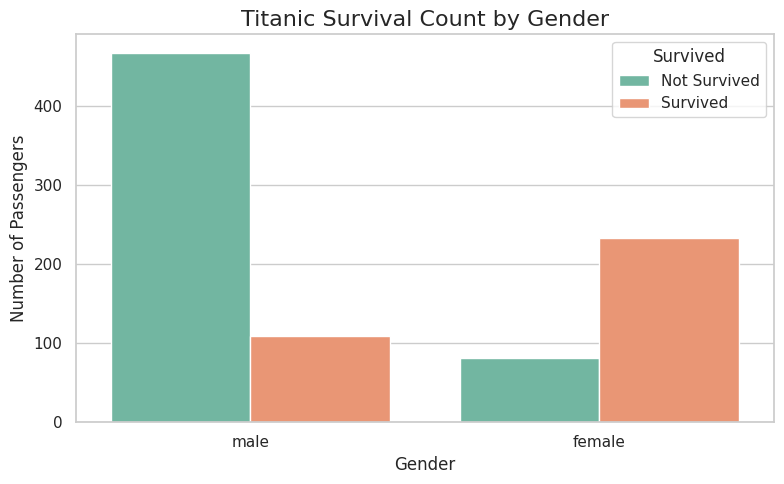

In [6]:

# BAR CHART: Survival by Gender

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Sex",
    hue="Survived",
    palette="Set2"
)

plt.title("Titanic Survival Count by Gender",
          fontsize=16)

plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(
    title="Survived",
    labels=["Not Survived", "Survived"]
)

plt.tight_layout()
plt.savefig("bar_chart.png", dpi=300)
plt.show()


### Observation – Bar Chart

The bar chart shows the survival distribution of male and female passengers on the Titanic. Female passengers had a higher survival rate than male passengers. This indicates that gender played an important role in passenger survival.

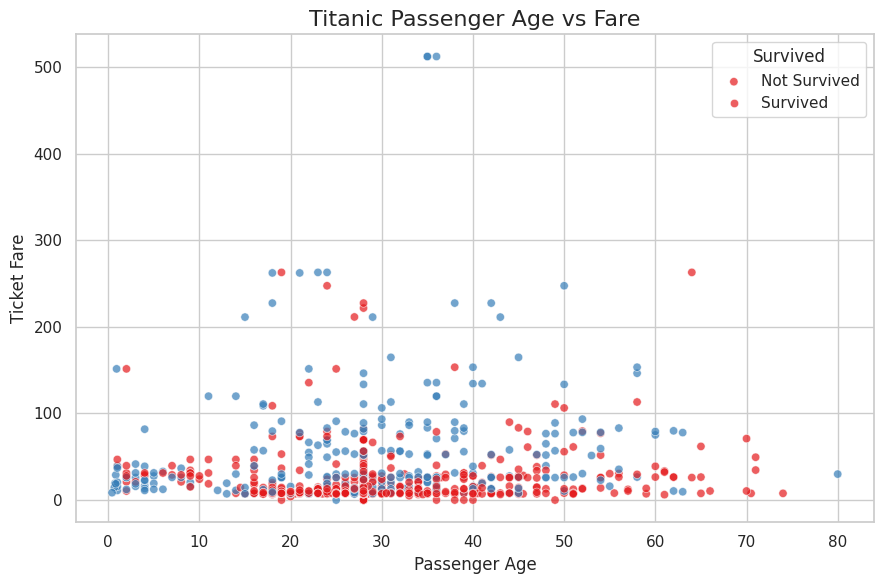

In [7]:

# SCATTER PLOT: Age vs Fare

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Fare",
    hue="Survived",
    palette="Set1",
    alpha=0.7
)

plt.title("Titanic Passenger Age vs Fare",
          fontsize=16)

plt.xlabel("Passenger Age")
plt.ylabel("Ticket Fare")

plt.legend(title="Survived",
           labels=["Not Survived", "Survived"])

plt.tight_layout()

plt.savefig("scatter_plot.png", dpi=300)

plt.show()


### Observation – Scatter Plot

The scatter plot shows the relationship between passenger age and ticket fare. Passengers paid different ticket fares across different age groups. The plot also displays the survival status of passengers using different colours.

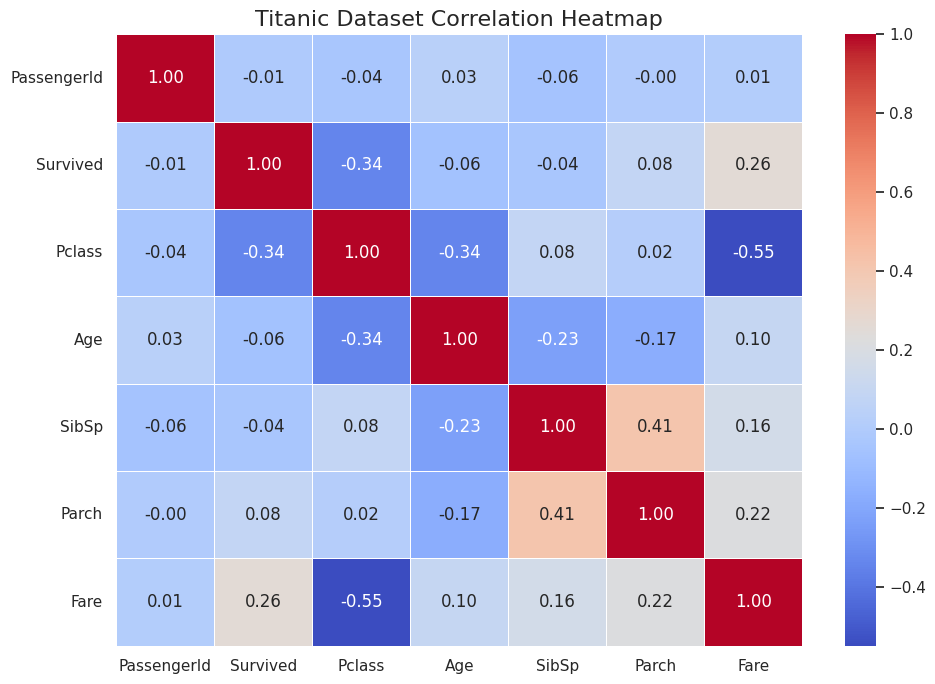

In [8]:

# CORRELATION HEATMAP

plt.figure(figsize=(10, 7))

# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Titanic Dataset Correlation Heatmap",
          fontsize=16)

plt.tight_layout()

plt.savefig("heatmap.png", dpi=300)

plt.show()


### Observation – Correlation Heatmap

The correlation heatmap displays relationships between numerical variables in the Titanic dataset. It helps identify positive and negative correlations between variables. Passenger class and fare show a negative relationship, while the heatmap also helps examine how other numerical features relate to survival.

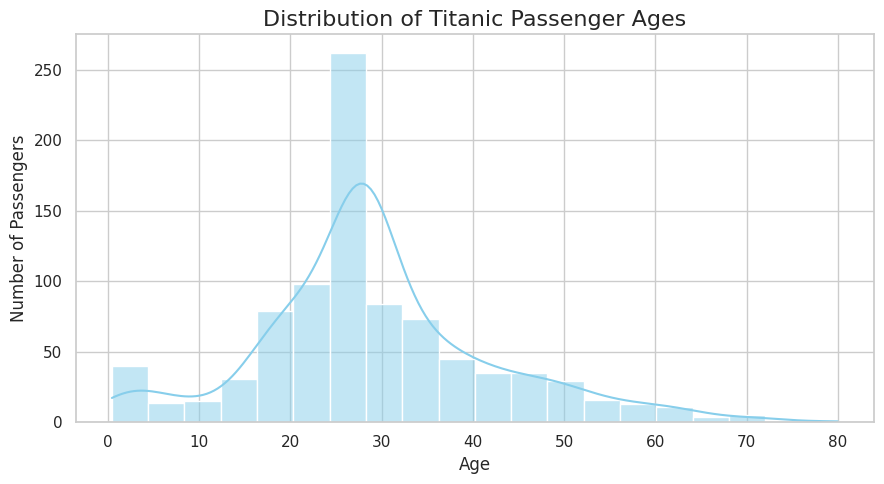

In [9]:

# HISTOGRAM: Passenger Age Distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True,
    color="skyblue"
)

plt.title("Distribution of Titanic Passenger Ages",
          fontsize=16)

plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.tight_layout()

plt.savefig("histogram.png", dpi=300)

plt.show()


### Observation – Histogram

The histogram displays the age distribution of Titanic passengers. It helps identify the most common age groups and understand how passenger ages are distributed.

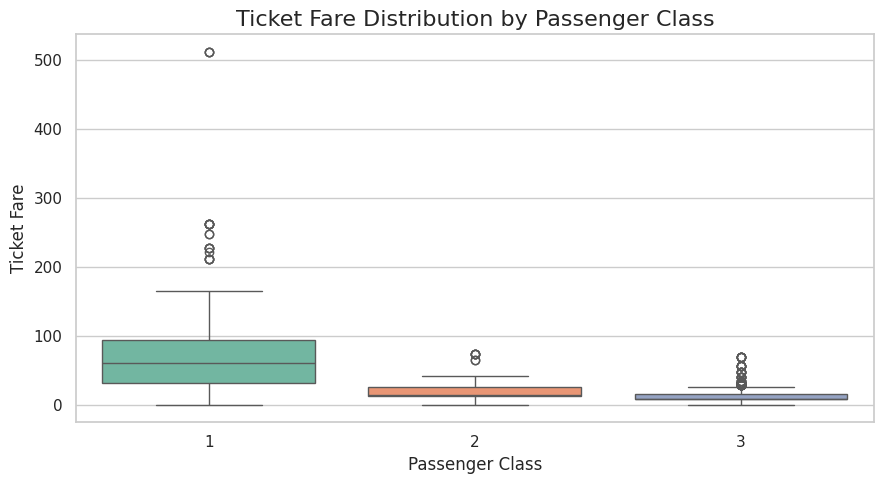

In [10]:

# BOX PLOT: Passenger Fare by Class

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Pclass",
    y="Fare",
    hue="Pclass",
    palette="Set2",
    legend=False
)

plt.title("Ticket Fare Distribution by Passenger Class",
          fontsize=16)

plt.xlabel("Passenger Class")
plt.ylabel("Ticket Fare")

plt.tight_layout()

plt.savefig("boxplot.png", dpi=300)

plt.show()


### Observation – Box Plot

The box plot compares ticket fares across the three passenger classes. It shows differences in fare distribution, including the median, spread, and possible outliers in each class.